
# Customer Churn Prediction Using Tree-Based Models

## Project Objective
Build, evaluate, compare, and explain machine learning models
that predict whether a telecommunications customer will churn.

## Project Workflow
1. Exploratory Data Analysis and Data Cleaning
2. Leakage-Safe Preprocessing and Data Splitting
3. Logistic Regression Baseline
4. Decision Trees: Gini vs. Entropy
5. Bagging and Random Forest
6. AdaBoost, Gradient Boosting, and XGBoost
7. Model Evaluation and SHAP Explainability
8. Deployment and Executive Reporting


In [2]:

# ============================================
# 1. IMPORT LIBRARIES AND SET REPRODUCIBILITY
# ============================================

import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# --------------------------------------------
# Filter the specific Jupyter deprecation warning
# --------------------------------------------
warnings.filterwarnings(
    "ignore",
    message=r".*datetime\.datetime\.utcnow\(\) is deprecated.*",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)
# Hide this specific SciPy L-BFGS-B deprecation warning.
warnings.filterwarnings(
    "ignore",
    message=r".*The `disp` and `iprint` options of the L-BFGS-B solver are deprecated.*",
    category=DeprecationWarning
)

# Keep other warnings visible for debugging.
# Do not add warnings.filterwarnings("ignore") globally.

# --------------------------------------------
# Reproducibility
# --------------------------------------------
RANDOM_STATE = 42

# --------------------------------------------
# Consistent pandas display settings
# --------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

# --------------------------------------------
# Environment information
# --------------------------------------------
print("Python version:", sys.version.split()[0])
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)


Python version: 3.13.15
pandas version: 2.3.3
NumPy version: 2.1.3
scikit-learn version: 1.6.1


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/WA_Fn-UseC_-Telco-Customer-Churn.csv


**Check the version of python and libraries**

In [4]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python version:", sys.version.split()[0])
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)

Python version: 3.13.15
pandas version: 2.3.3
NumPy version: 2.1.3
scikit-learn version: 1.6.1


**Loading the Dataset into Pandas**

In [6]:

from pathlib import Path
import pandas as pd

# Path to the dataset attached to your Kaggle notebook.
DATA_PATH = Path(
    "/kaggle/input/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Check that the dataset exists before loading.
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Load the CSV file into a pandas DataFrame.
df = pd.read_csv(DATA_PATH)

# Verify the dimensions and preview the records.
print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully.
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [28]:

# Review column names, data types, and non-null counts.
df.info()

# Summarize numerical columns.
display(df.describe())

# Count missing values in every column.
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False))

# Count completely duplicated rows.
print("Duplicate rows:", df.duplicated().sum())

# Check the target variable's distribution.
print("Churn distribution:")
display(df["Churn"].value_counts(dropna=False))

print("Churn proportions:")
display(df["Churn"].value_counts(normalize=True, dropna=False).mul(100).round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000,7043.000,7043.000
mean,0.162,32.371,64.762
std,0.369,24.559,30.090
min,0.000,0.000,18.250
25%,0.000,9.000,35.500
50%,0.000,29.000,70.350
75%,0.000,55.000,89.850
max,1.000,72.000,118.750


Missing values by column:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn proportions:


Churn
No    73.460
Yes   26.540
Name: proportion, dtype: float64

**Investigating and Cleaning TotalCharges.**

In [7]:

# Inspect the original values before making any changes.
print("TotalCharges data type:", df["TotalCharges"].dtype)

print("\nFirst 15 original values:")
display(df["TotalCharges"].head(15))

# Count strings that are empty or contain only whitespace.
blank_mask = (
    df["TotalCharges"]
    .astype("string")
    .str.strip()
    .eq("")
    .fillna(False)
)

print("\nBlank or whitespace-only TotalCharges:", blank_mask.sum())

# Investigate whether blank charges are associated with zero tenure.
print("\nTenure for records with blank TotalCharges:")
display(df.loc[blank_mask, ["tenure", "TotalCharges"]])

# Count zero-tenure customers.
print("\nCustomers with zero tenure:", (df["tenure"] == 0).sum())

# Display all columns for zero-tenure customers.
display(
    df.loc[df["tenure"] == 0,
           ["customerID", "tenure", "MonthlyCharges",
            "TotalCharges", "Churn"]]
)


TotalCharges data type: object

First 15 original values:


0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
Name: TotalCharges, dtype: object


Blank or whitespace-only TotalCharges: 11

Tenure for records with blank TotalCharges:


,tenure,TotalCharges
488,0,
753,0,
936,0,
1082,0,
1340,0,
3331,0,
3826,0,
4380,0,
5218,0,
6670,0,



Customers with zero tenure: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.550,,No
753,3115-CZMZD,0,20.250,,No
936,5709-LVOEQ,0,80.850,,No
1082,4367-NUYAO,0,25.750,,No
1340,1371-DWPAZ,0,56.050,,No
3331,7644-OMVMY,0,19.850,,No
3826,3213-VVOLG,0,25.350,,No
4380,2520-SGTTA,0,20.000,,No
5218,2923-ARZLG,0,19.700,,No
6670,4075-WKNIU,0,73.350,,No


**Convert TotalCharges to Numeric and Handle Blank Value**

In [8]:

# Keep the original values for auditing the cleaning process.
total_charges_original = df["TotalCharges"].copy()

# Convert whitespace-only strings to missing values.
total_charges_clean = (
    df["TotalCharges"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Convert the cleaned values to numeric.
df["TotalCharges"] = pd.to_numeric(
    total_charges_clean,
    errors="coerce"
)

# Count values that could not be converted.
newly_missing = (
    total_charges_original.notna()
    & df["TotalCharges"].isna()
)

print("Values that could not be converted:", newly_missing.sum())
print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isna().sum())

# Apply a domain-based rule to zero-tenure customers.
# Their blank cumulative charges are treated as zero under this assumption.
zero_tenure_missing = (
    df["tenure"].eq(0)
    & df["TotalCharges"].isna()
)

print("Missing charges among zero-tenure customers:",
      zero_tenure_missing.sum())

df.loc[zero_tenure_missing, "TotalCharges"] = 0.0

# Verify the cleaning result.
print("\nTotalCharges data type:", df["TotalCharges"].dtype)
print("Remaining missing TotalCharges:",
      df["TotalCharges"].isna().sum())

display(
    df.loc[zero_tenure_missing,
           ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
)


Values that could not be converted: 11
Missing TotalCharges after conversion: 11
Missing charges among zero-tenure customers: 11

TotalCharges data type: Float64
Remaining missing TotalCharges: 0


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.550,0.000,No
753,0,20.250,0.000,No
936,0,80.850,0.000,No
1082,0,25.750,0.000,No
1340,0,56.050,0.000,No
3331,0,19.850,0.000,No
3826,0,25.350,0.000,No
4380,0,20.000,0.000,No
5218,0,19.700,0.000,No
6670,0,73.350,0.000,No


**Feature and Target Preparation**

In [9]:

# Create a separate feature table without modifying the cleaned DataFrame.
X = df.drop(columns=["Churn", "customerID"]).copy()

# Create the target labels.
y = df["Churn"].map({"No": 0, "Yes": 1})

# Verify that the target mapping worked.
if y.isna().any():
    raise ValueError("Unexpected or missing labels found in Churn.")

# Inspect the resulting features and target.
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class counts:")
display(y.value_counts().sort_index())

print("\nTarget class percentages:")
display((y.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nFeature data types:")
display(X.dtypes)


Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target class counts:


Churn
0    5174
1    1869
Name: count, dtype: int64


Target class percentages:


Churn
0   73.460
1   26.540
Name: proportion, dtype: float64


Feature data types:


gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        Float64
dtype: object

**Stratified Train, Validation, and Test Split.**

In [10]:

from sklearn.model_selection import train_test_split

# First, reserve 20% of the data as the final test set.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split the remaining 80% into training and validation.
# 0.25 × 0.80 = 0.20 of the original dataset.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train_val
)

# Display the split sizes and churn rates.
splits = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

for split_name, (X_part, y_part) in splits.items():
    print(
        f"{split_name:10s} | "
        f"Rows: {len(X_part):4d} | "
        f"Churn rate: {y_part.mean() * 100:.2f}%"
    )

# Verify that the partitions contain all original rows.
assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert len(y_train) + len(y_val) + len(y_test) == len(y)
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty

print("\nSplit checks passed: no overlapping rows.")


Train      | Rows: 4225 | Churn rate: 26.53%
Validation | Rows: 1409 | Churn rate: 26.54%
Test       | Rows: 1409 | Churn rate: 26.54%

Split checks passed: no overlapping rows.


**Leakage-Safe Preprocessing.**

In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns from the feature table.
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))
print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

# Numerical preprocessing:
# - Fill missing values using the training-set median.
# - Standardize features for Logistic Regression.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# - Fill missing values using the most frequent training category.
# - Encode categories into binary columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature group.
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessor defined successfully.")


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15

Preprocessor defined successfully.


**Baseline Model — Logistic Regression**

In [12]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Combine preprocessing and Logistic Regression.
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# Fit the complete pipeline using training data only.
logistic_model.fit(X_train, y_train)

# Predict class labels and churn probabilities on validation data.
y_val_pred = logistic_model.predict(X_val)
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

# Evaluate validation performance.
print("VALIDATION RESULTS — LOGISTIC REGRESSION")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_proba):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Stayed (0)", "Churned (1)"],
    zero_division=0
))


VALIDATION RESULTS — LOGISTIC REGRESSION
---------------------------------------------
Accuracy:  0.8027
Precision: 0.6579
Recall:    0.5348
F1-score:  0.5900
ROC-AUC:   0.8360

Confusion matrix:
[[931 104]
 [174 200]]

Classification report:
              precision    recall  f1-score   support

  Stayed (0)       0.84      0.90      0.87      1035
 Churned (1)       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [14]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Confirm that the validation probabilities already exist.
if "y_val_proba" not in globals():
    raise NameError(
        "y_val_proba is missing. Run the Logistic Regression "
        "training and validation prediction cells first."
    )

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]
threshold_rows = []

for threshold in thresholds:
    # Predict churn when the probability meets the threshold.
    predictions = (y_val_proba >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "customers_flagged": int(predictions.sum()),
    })

# Create the DataFrame before trying to display it.
threshold_results = pd.DataFrame(threshold_rows)

print(
    threshold_results.to_string(
        index=False,
        formatters={
            "threshold": "{:.2f}".format,
            "accuracy": "{:.3f}".format,
            "precision": "{:.3f}".format,
            "recall": "{:.3f}".format,
            "f1": "{:.3f}".format,
        },
    )
)


threshold accuracy precision recall    f1  customers_flagged
     0.30    0.762     0.536  0.751 0.626                524
     0.35    0.779     0.567  0.706 0.629                466
     0.40    0.789     0.595  0.644 0.619                405
     0.45    0.801     0.633  0.591 0.611                349
     0.50    0.803     0.658  0.535 0.590                304
     0.55    0.806     0.691  0.484 0.569                262


In [16]:
# Provisional threshold selected using validation data.
SELECTED_THRESHOLD = 0.35

# Convert validation probabilities into churn predictions.
y_val_pred_selected = (
    y_val_proba >= SELECTED_THRESHOLD
).astype(int)

print(f"Selected threshold: {SELECTED_THRESHOLD:.2f}")
print(f"Validation recall: {recall_score(y_val, y_val_pred_selected):.3f}")
print(f"Validation precision: {precision_score(y_val, y_val_pred_selected):.3f}")
print(f"Validation F1-score: {f1_score(y_val, y_val_pred_selected):.3f}")

Selected threshold: 0.35
Validation recall: 0.706
Validation precision: 0.567
Validation F1-score: 0.629


**Train and compare Gini and entropy**

In [21]:

import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# Define both decision tree models.
tree_models = {
    "Decision Tree - Gini": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            random_state=RANDOM_STATE
        )),
    ]),
    "Decision Tree - Entropy": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion="entropy",
            random_state=RANDOM_STATE
        )),
    ]),
}

tree_results = []

# Train on training data and evaluate on validation data.
for model_name, model in tree_models.items():
    model.fit(X_train, y_train)

    val_predictions = model.predict(X_val)
    val_probabilities = model.predict_proba(X_val)[:, 1]

    fitted_tree = model.named_steps["classifier"]

    tree_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_val, val_predictions),
        "precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_probabilities),
        "tree_depth": fitted_tree.get_depth(),
        "leaf_nodes": fitted_tree.get_n_leaves(),
    })

tree_comparison = pd.DataFrame(tree_results)

display(
    tree_comparison
    .round(3)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)


,model,accuracy,precision,recall,f1,roc_auc,tree_depth,leaf_nodes
0,Decision Tree - Entropy,0.752,0.533,0.521,0.527,0.678,35,784
1,Decision Tree - Gini,0.745,0.520,0.519,0.519,0.673,23,784


**Compare depths 2, 5, and unlimited**

In [23]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
import pandas as pd

depth_values = [2, 5, None]
depth_results = []
depth_models = {}

for depth in depth_values:
    model_name = (
        "Unlimited" if depth is None else f"Depth {depth}"
    )

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            random_state=RANDOM_STATE,
        )),
    ])

    # Fit using training data only.
    model.fit(X_train, y_train)

    # Evaluate training performance.
    train_predictions = model.predict(X_train)
    train_probabilities = model.predict_proba(X_train)[:, 1]

    # Evaluate validation performance.
    val_predictions = model.predict(X_val)
    val_probabilities = model.predict_proba(X_val)[:, 1]

    fitted_tree = model.named_steps["classifier"]

    depth_results.append({
        "model": model_name,
        "max_depth_setting": (
            "None" if depth is None else depth
        ),
        "actual_depth": fitted_tree.get_depth(),
        "leaf_nodes": fitted_tree.get_n_leaves(),
        "train_accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "val_accuracy": accuracy_score(
            y_val, val_predictions
        ),
        "train_f1": f1_score(
            y_train, train_predictions, zero_division=0
        ),
        "val_f1": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "val_recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "val_roc_auc": roc_auc_score(
            y_val, val_probabilities
        ),
    })

    depth_models[model_name] = model

depth_comparison = pd.DataFrame(depth_results)


# Check the column names and display the actual values.
print("Columns:", depth_comparison.columns.tolist())
print()
print(depth_comparison.to_string(index=False))

Columns: ['model', 'max_depth_setting', 'actual_depth', 'leaf_nodes', 'train_accuracy', 'val_accuracy', 'train_f1', 'val_f1', 'val_recall', 'val_roc_auc']

    model max_depth_setting  actual_depth  leaf_nodes  train_accuracy  val_accuracy  train_f1  val_f1  val_recall  val_roc_auc
  Depth 2                 2             2           4           0.768         0.759     0.590   0.579       0.626        0.780
  Depth 5                 5             5          30           0.812         0.787     0.598   0.537       0.465        0.814
Unlimited              None            23         784           0.998         0.745     0.997   0.519       0.519        0.673


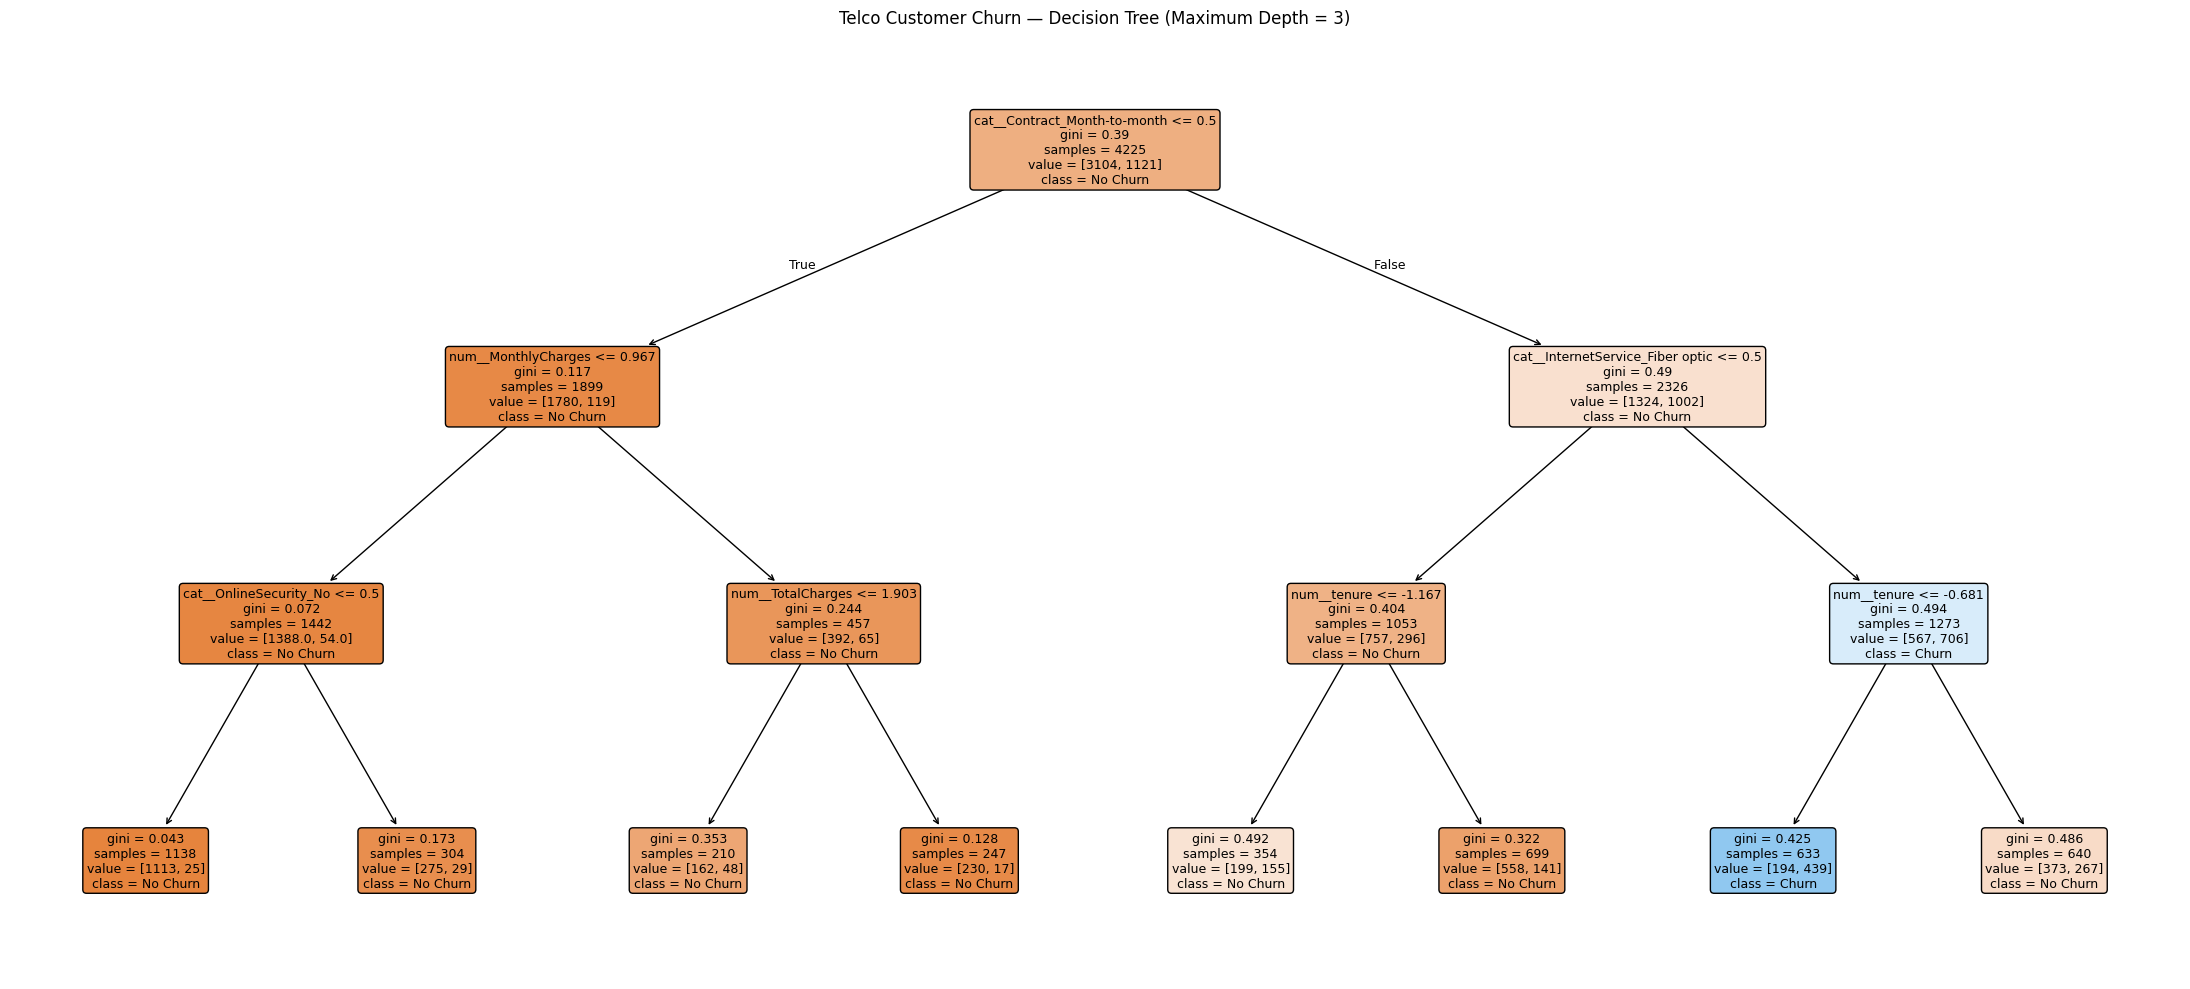

In [24]:

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline

# Build a shallow, interpretable decision tree.
tree_depth_3 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

# Fit only on the training data.
tree_depth_3.fit(X_train, y_train)

# Retrieve the fitted preprocessing and tree components.
fitted_preprocessor = tree_depth_3.named_steps["preprocessor"]
fitted_tree = tree_depth_3.named_steps["classifier"]

# Get the feature names after one-hot encoding.
feature_names = fitted_preprocessor.get_feature_names_out()

# Display the tree.
plt.figure(figsize=(22, 10))
plot_tree(
    fitted_tree,
    feature_names=feature_names,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Telco Customer Churn — Decision Tree (Maximum Depth = 3)")
plt.tight_layout()
plt.show()


# Bagging and Random Forest

## Objective

Improve on a single decision tree by combining multiple trees. We will evaluate a Bagging Classifier and a Random Forest using the same training and validation sets as earlier experiments.

## Key concepts

**Bootstrap sampling:** Create a sample by randomly drawing training observations with replacement. Some observations may appear multiple times, while others may be left out.

**Bagging (Bootstrap Aggregating):** Train multiple base estimators on bootstrap samples and combine their predictions. For classification, predictions are commonly aggregated through voting or predicted probabilities.

**Random Forest:** Combines bagging with random feature selection at each split. This helps reduce similarity between individual trees.

**Business relevance:** A more stable churn model may help a retention team prioritize customers. We will evaluate recall and F1 alongside accuracy and ROC-AUC, since missing likely churners may be costly.

**Experimental rule:** Fit models using training data, compare them on validation data, and leave the test set untouched until final evaluation.

In [26]:

import pandas as pd

from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Bagging: multiple decision trees trained on bootstrap samples.
bagging_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100,
        max_samples=1.0,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Random Forest: bagging plus random feature selection at each split.
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

ensemble_models = {
    "Bagging": bagging_model,
    "Random Forest": random_forest_model
}

print("Ensemble pipelines created.")


Ensemble pipelines created.


In [27]:

ensemble_results = []

for model_name, model in ensemble_models.items():
    # Fit only on training data.
    model.fit(X_train, y_train)

    # Evaluate on validation data.
    val_predictions = model.predict(X_val)
    val_probabilities = model.predict_proba(X_val)[:, 1]

    ensemble_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_val, val_predictions),
        "precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_probabilities)
    })

ensemble_comparison = (
    pd.DataFrame(ensemble_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

display(ensemble_comparison.round(3))


,model,accuracy,precision,recall,f1,roc_auc
0,Bagging,0.786,0.633,0.465,0.536,0.814
1,Random Forest,0.781,0.616,0.463,0.528,0.812


In [28]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Define a small set of configurations to compare.
rf_configs = [
    {"n_estimators": 100, "max_depth": 5,  "max_features": "sqrt"},
    {"n_estimators": 200, "max_depth": 5,  "max_features": "sqrt"},
    {"n_estimators": 100, "max_depth": 10, "max_features": "sqrt"},
    {"n_estimators": 200, "max_depth": 10, "max_features": "sqrt"},
    {"n_estimators": 200, "max_depth": None, "max_features": "sqrt"},
    {"n_estimators": 200, "max_depth": 10, "max_features": 0.5},
]

rf_tuning_results = []

for config in rf_configs:
    rf_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            **config,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    rf_pipeline.fit(X_train, y_train)

    val_pred = rf_pipeline.predict(X_val)
    val_proba = rf_pipeline.predict_proba(X_val)[:, 1]

    rf_tuning_results.append({
        **config,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_proba)
    })

rf_tuning_comparison = (
    pd.DataFrame(rf_tuning_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

display(rf_tuning_comparison.round(3))


,n_estimators,max_depth,max_features,accuracy,precision,recall,f1,roc_auc
0,100,10.000,sqrt,0.796,0.663,0.473,0.552,0.831
1,200,10.000,sqrt,0.794,0.657,0.471,0.548,0.832
2,200,10.000,0.500,0.791,0.651,0.455,0.535,0.832
3,200,NaN,sqrt,0.779,0.611,0.463,0.527,0.814
4,100,5.000,sqrt,0.792,0.704,0.374,0.489,0.836
5,200,5.000,sqrt,0.791,0.698,0.372,0.485,0.837


**Out-of-bag evaluation (OOB)**

In [29]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

# OOB evaluation requires bootstrap sampling.
# Use the strongest F1 configuration from the tuning experiment.
rf_oob_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        max_features="sqrt",
        bootstrap=True,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Fit using training data only.
rf_oob_model.fit(X_train, y_train)

# Extract the fitted classifier.
rf_oob_classifier = rf_oob_model.named_steps["classifier"]

print(f"OOB accuracy estimate: {rf_oob_classifier.oob_score_:.3f}")

# Compare OOB accuracy with validation accuracy.
val_predictions_oob_model = rf_oob_model.predict(X_val)

print(
    "Validation accuracy: "
    f"{accuracy_score(y_val, val_predictions_oob_model):.3f}"
)


OOB accuracy estimate: 0.797
Validation accuracy: 0.796


**extract and plot the top 15 features**

Top 15 transformed features:


,feature,importance
0,num__tenure,0.136
1,num__TotalCharges,0.124
2,num__MonthlyCharges,0.095
3,cat__Contract_Month-to-month,0.090
4,cat__OnlineSecurity_No,0.049
5,cat__InternetService_Fiber optic,0.049
6,cat__PaymentMethod_Electronic check,0.040
7,cat__TechSupport_No,0.035
8,cat__Contract_Two year,0.034
9,cat__OnlineBackup_No,0.019


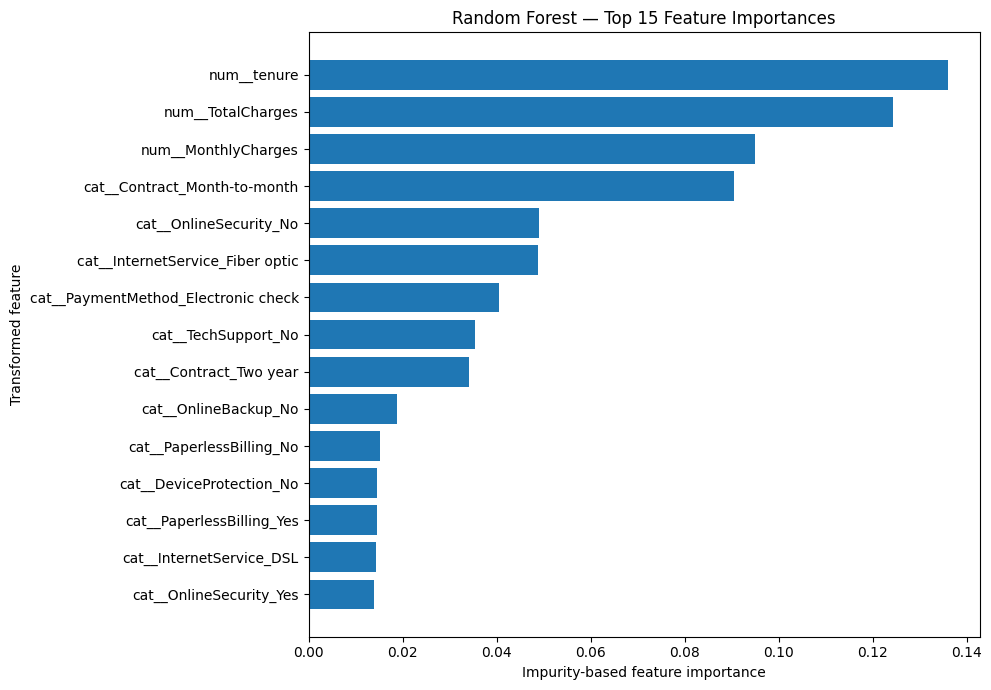

In [30]:

import pandas as pd
import matplotlib.pyplot as plt

# Get the transformed feature names and fitted model importances.
transformed_feature_names = (
    rf_oob_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importances = (
    rf_oob_model
    .named_steps["classifier"]
    .feature_importances_
)

# Build a ranked table of transformed features.
rf_feature_importance = (
    pd.DataFrame({
        "feature": transformed_feature_names,
        "importance": feature_importances
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 transformed features:")
display(rf_feature_importance.head(15).round(4))

# Plot the top 15 features for easier interpretation.
top_features = rf_feature_importance.head(15).sort_values(
    "importance", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Impurity-based feature importance")
plt.ylabel("Transformed feature")
plt.title("Random Forest — Top 15 Feature Importances")
plt.tight_layout()
plt.show()


# Boosting Models

## Objective

Compare AdaBoost and Gradient Boosting with the earlier decision tree, Bagging, and Random Forest models. We will evaluate validation accuracy, precision, recall, F1, and ROC-AUC.

## Key concepts

**Boosting** combines weak or moderately accurate learners sequentially. Each new learner aims to improve the current ensemble.

**AdaBoost** adjusts the importance of training observations based on earlier mistakes.

**Gradient Boosting** adds learners that optimize a loss function through gradient-based updates.

**Learning rate** controls the contribution of each new learner. Smaller values generally require more boosting stages.

**Overfitting control:** The number of estimators, tree depth, learning rate, and other settings must be selected without using the final test set.

We will keep the existing training and validation splits and leave the test set untouched.


**Building the initial Boosting Models**

In [31]:

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

boosting_models = {
    "AdaBoost": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=1,
                random_state=RANDOM_STATE
            ),
            n_estimators=100,
            learning_rate=0.5,
            random_state=RANDOM_STATE
        ))
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=2,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Boosting pipelines created.")


Boosting pipelines created.


**train and compare validation metrics**

In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

boosting_results = []

for model_name, model in boosting_models.items():
    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]

    boosting_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_proba)
    })

boosting_comparison = (
    pd.DataFrame(boosting_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

display(boosting_comparison.round(3))


,model,accuracy,precision,recall,f1,roc_auc
0,AdaBoost,0.803,0.658,0.535,0.590,0.837
1,Gradient Boosting,0.798,0.658,0.500,0.568,0.839


# Tune AdaBoost and Gradient Boosting

**AdaBoost tuning**

In [33]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

adaboost_configs = [
    {"n_estimators": 50,  "learning_rate": 0.1, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.5, "max_depth": 1},
    {"n_estimators": 200, "learning_rate": 0.5, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 1.0, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.5, "max_depth": 2},
]

adaboost_tuning_results = []

for config in adaboost_configs:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=config["max_depth"],
                random_state=RANDOM_STATE
            ),
            n_estimators=config["n_estimators"],
            learning_rate=config["learning_rate"],
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]

    adaboost_tuning_results.append({
        **config,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_proba)
    })

adaboost_tuning_comparison = (
    pd.DataFrame(adaboost_tuning_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

display(adaboost_tuning_comparison.round(3))


,n_estimators,learning_rate,max_depth,accuracy,precision,recall,f1,roc_auc
0,200,0.500,1,0.805,0.667,0.529,0.590,0.839
1,100,0.500,1,0.803,0.658,0.535,0.590,0.837
2,100,0.500,2,0.801,0.656,0.529,0.586,0.837
3,100,1.000,1,0.798,0.654,0.511,0.574,0.839
4,50,0.100,1,0.735,0.000,0.000,0.000,0.822


**tune Gradient Boosting**

In [34]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

gb_configs = [
    {"n_estimators": 50,  "learning_rate": 0.05, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 2},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 3},
]

gb_tuning_results = []

for config in gb_configs:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=config["n_estimators"],
            learning_rate=config["learning_rate"],
            max_depth=config["max_depth"],
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]

    gb_tuning_results.append({
        **config,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_proba)
    })

gb_tuning_comparison = (
    pd.DataFrame(gb_tuning_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

display(gb_tuning_comparison.round(3))


,n_estimators,learning_rate,max_depth,accuracy,precision,recall,f1,roc_auc
0,100,0.100,3,0.802,0.669,0.503,0.574,0.841
1,200,0.050,2,0.801,0.664,0.503,0.572,0.839
2,100,0.100,2,0.798,0.658,0.500,0.568,0.839
3,100,0.050,1,0.793,0.716,0.364,0.482,0.834
4,50,0.050,1,0.771,0.771,0.198,0.315,0.831


### Gradient Boosting: Training Versus Validation Performance

We will examine training and validation F1 as the number of boosting estimators increases.

If training F1 improves while validation F1 stops improving or declines, the model may be overfitting. If both scores remain low, the model may be underfitting. The best estimator count should be selected using validation performance rather than training performance alone.

This experiment uses the same training and validation splits as the earlier comparisons. The test set remains untouched.

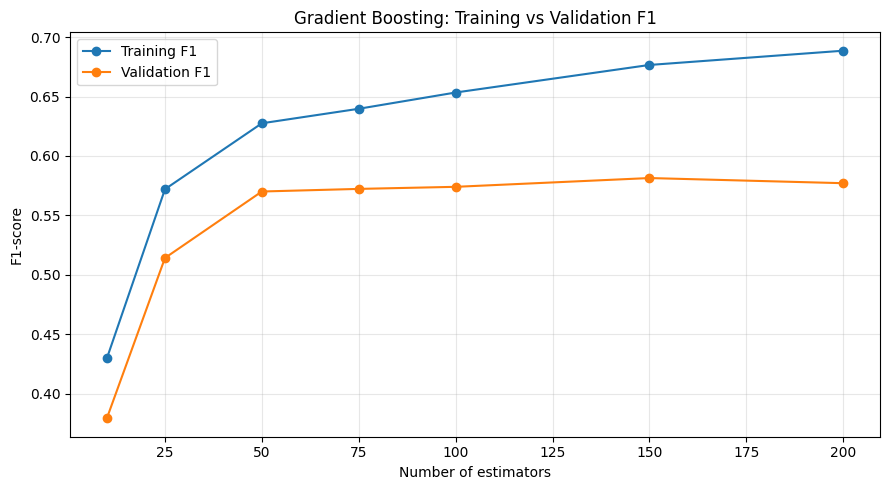

,n_estimators,train_f1,val_f1
0,10,0.430,0.379
1,25,0.572,0.514
2,50,0.628,0.570
3,75,0.640,0.572
4,100,0.653,0.574
5,150,0.677,0.581
6,200,0.689,0.577


In [35]:

import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score

estimator_counts = [10, 25, 50, 75, 100, 150, 200]

train_f1_scores = []
val_f1_scores = []

for n_estimators in estimator_counts:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=n_estimators,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_f1_scores.append(
        f1_score(y_train, train_pred, zero_division=0)
    )
    val_f1_scores.append(
        f1_score(y_val, val_pred, zero_division=0)
    )

plt.figure(figsize=(9, 5))
plt.plot(
    estimator_counts, train_f1_scores,
    marker="o", label="Training F1"
)
plt.plot(
    estimator_counts, val_f1_scores,
    marker="o", label="Validation F1"
)
plt.xlabel("Number of estimators")
plt.ylabel("F1-score")
plt.title("Gradient Boosting: Training vs Validation F1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show the underlying values as a table.
gb_learning_curve = pd.DataFrame({
    "n_estimators": estimator_counts,
    "train_f1": train_f1_scores,
    "val_f1": val_f1_scores
})

display(gb_learning_curve.round(3))


### XGBoost: Environment Check

XGBoost is a gradient-boosting library designed for efficient tree-based machine learning. We will first check whether it is installed and identify its version.

Checking the environment before importing or installing a dependency improves reproducibility and helps avoid unnecessary package changes.

In [36]:
# Check whether XGBoost is available in this environment.
try:
    import xgboost as xgb

    print("XGBoost is installed.")
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed.")

XGBoost is installed.
XGBoost version: 3.4.1


### XGBoost: Baseline Model

We will train an XGBoost classifier using a preprocessing pipeline and evaluate it on the validation set.

**Initial hyperparameters**
- `n_estimators=200`: maximum number of boosting trees.
- `max_depth=3`: limits the depth of each tree.
- `learning_rate=0.05`: controls each tree's contribution to the ensemble.
- `subsample=0.8`: samples 80% of training rows for each boosting iteration.
- `colsample_bytree=0.8`: samples 80% of features for each tree.
- `eval_metric="logloss"`: monitors the quality of predicted probabilities during optimization.

These are starting values, not guaranteed optimal settings. We will compare the resulting validation metrics with our existing models.

In [37]:
# Train a baseline XGBoost model and evaluate it on validation data.

import pandas as pd

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Build a complete pipeline so preprocessing is applied consistently.
xgboost_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Fit only on training data.
xgboost_model.fit(X_train, y_train)

# Evaluate on validation data, not the held-out test set.
xgb_val_pred = xgboost_model.predict(X_val)
xgb_val_proba = xgboost_model.predict_proba(X_val)[:, 1]

xgb_metrics = {
    "model": "XGBoost",
    "accuracy": accuracy_score(y_val, xgb_val_pred),
    "precision": precision_score(
        y_val, xgb_val_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, xgb_val_pred, zero_division=0
    ),
    "f1": f1_score(
        y_val, xgb_val_pred, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_val, xgb_val_proba)
}

display(pd.DataFrame([xgb_metrics]).round(3))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val, xgb_val_pred))

print("\nClassification report:")
print(classification_report(
    y_val,
    xgb_val_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

,model,accuracy,precision,recall,f1,roc_auc
0,XGBoost,0.803,0.671,0.503,0.575,0.840


Confusion matrix (rows = actual, columns = predicted):
[[943  92]
 [186 188]]

Classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



### XGBoost: Hyperparameter Tuning

Hyperparameter tuning evaluates different model configurations to find a useful balance between predictive performance and generalization.

We will compare a small set of configurations on the same training and validation splits.

- `n_estimators` controls the number of boosting rounds.
- `max_depth` controls individual tree complexity.
- `learning_rate` controls the contribution of each boosting round.
- `subsample` controls the fraction of training rows sampled per round.
- `colsample_bytree` controls the fraction of features sampled per tree.

We will rank the configurations primarily by validation F1, while monitoring ROC-AUC, precision, and recall. This is an initial manual search, not an exhaustive or cross-validated hyperparameter search.

In [38]:
# Compare a small, predefined set of XGBoost configurations.
# All configurations use the same training and validation splits.

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

xgb_configs = [
    {
        "n_estimators": 100,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 200,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 200,
        "max_depth": 2,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    }
]

xgb_tuning_results = []

for config in xgb_configs:
    candidate = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **config
        ))
    ])

    candidate.fit(X_train, y_train)

    val_pred = candidate.predict(X_val)
    val_proba = candidate.predict_proba(X_val)[:, 1]

    xgb_tuning_results.append({
        **config,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_proba)
    })

xgb_tuning_results = pd.DataFrame(xgb_tuning_results)

# Rank configurations by validation F1, then ROC-AUC.
xgb_tuning_results = xgb_tuning_results.sort_values(
    by=["f1", "roc_auc"],
    ascending=False
).reset_index(drop=True)

display(xgb_tuning_results.round(3))

,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,accuracy,precision,recall,f1,roc_auc
0,200,4,0.030,0.800,0.800,0.805,0.676,0.508,0.580,0.841
1,200,2,0.050,0.800,0.800,0.803,0.670,0.511,0.580,0.841
2,200,3,0.050,0.800,0.800,0.803,0.671,0.503,0.575,0.840
3,100,3,0.050,0.800,0.800,0.803,0.675,0.495,0.571,0.840


### XGBoost: Training vs. Validation Learning Curve

We will compare training and validation F1 at several estimator counts while keeping the other hyperparameters fixed.

If training F1 keeps increasing while validation F1 levels off or declines, adding more trees may be increasing model complexity without improving generalization.

This experiment uses `max_depth=2` and `learning_rate=0.05`, one of the strongest configurations in our initial tuning. The estimator count will vary from 50 to 300.

The validation curve helps guide the choice of estimator count, but a small validation improvement may not be practically meaningful.

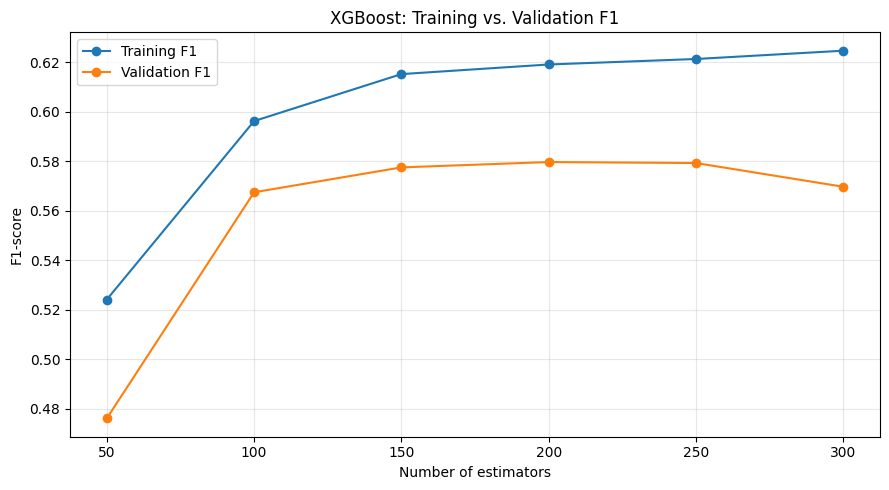

,n_estimators,train_f1,val_f1
0,50,0.524,0.476
1,100,0.596,0.567
2,150,0.615,0.578
3,200,0.619,0.580
4,250,0.621,0.579
5,300,0.625,0.570


In [39]:
import matplotlib.pyplot as plt
import pandas as pd

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score

estimator_counts = [50, 100, 150, 200, 250, 300]

xgb_train_f1 = []
xgb_val_f1 = []

for n_estimators in estimator_counts:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=n_estimators,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    xgb_train_f1.append(
        f1_score(y_train, train_pred, zero_division=0)
    )
    xgb_val_f1.append(
        f1_score(y_val, val_pred, zero_division=0)
    )

# Plot training and validation F1.
plt.figure(figsize=(9, 5))
plt.plot(
    estimator_counts, xgb_train_f1,
    marker="o", label="Training F1"
)
plt.plot(
    estimator_counts, xgb_val_f1,
    marker="o", label="Validation F1"
)

plt.xlabel("Number of estimators")
plt.ylabel("F1-score")
plt.title("XGBoost: Training vs. Validation F1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display the exact values behind the plot.
xgb_learning_curve = pd.DataFrame({
    "n_estimators": estimator_counts,
    "train_f1": xgb_train_f1,
    "val_f1": xgb_val_f1
})

display(xgb_learning_curve.round(3))

## Final Test-Set Evaluation

The purpose of final evaluation is to estimate how the selected models perform on unseen data.

We will:
1. Rebuild the candidate pipelines with the selected hyperparameters.
2. Fit each pipeline on the combined training and validation data.
3. Evaluate each fitted pipeline on the untouched test set.
4. Calculate accuracy, precision, recall, F1-score, and ROC-AUC.
5. Display a confusion matrix for each model.

For this initial comparison, all models use the default classification threshold of 0.50. The test results will not be used to tune hyperparameters or select a new threshold.

**Important:** The test set represents unseen data only if it has not previously been used to choose models, thresholds, or hyperparameters.

In [40]:
# final test-set evaluation.
# Assumes X_train_val, y_train_val, X_test, y_test,
# preprocessor, and RANDOM_STATE already exist.

import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Define final candidate pipelines.
# Each pipeline learns preprocessing from its own training data.
final_models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree (depth 2)": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=2,
            random_state=RANDOM_STATE
        ))
    ]),

    "Bagging": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", BaggingClassifier(
            estimator=DecisionTreeClassifier(
                random_state=RANDOM_STATE
            ),
            n_estimators=100,
            max_samples=1.0,
            bootstrap=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "AdaBoost": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=1,
                random_state=RANDOM_STATE
            ),
            n_estimators=100,
            learning_rate=0.5,
            random_state=RANDOM_STATE
        ))
    ]),

    "Gradient Boosting": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=200,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

test_results = []
test_confusion_matrices = {}

for model_name, model in final_models.items():
    # Fit only on training + validation data.
    model.fit(X_train_val, y_train_val)

    # Evaluate on the untouched test set.
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, test_pred),
        "precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "f1": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, test_proba)
    })

    test_confusion_matrices[model_name] = confusion_matrix(
        y_test, test_pred
    )

test_results = pd.DataFrame(test_results)

display(
    test_results
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
    .round(3)
)

# Show each model's confusion matrix separately.
for model_name, matrix in test_confusion_matrices.items():
    print(f"\n{model_name} — confusion matrix")
    print("Rows = actual [No Churn, Churn]")
    print("Columns = predicted [No Churn, Churn]")
    print(matrix)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,XGBoost,0.807,0.680,0.516,0.587,0.847
2,Random Forest,0.801,0.659,0.516,0.579,0.838
3,Gradient Boosting,0.798,0.649,0.519,0.577,0.840
4,AdaBoost,0.793,0.633,0.527,0.575,0.839
5,Decision Tree (depth 2),0.751,0.527,0.594,0.558,0.780
6,Bagging,0.781,0.607,0.500,0.548,0.813



Logistic Regression — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[926 109]
 [165 209]]

Decision Tree (depth 2) — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[836 199]
 [152 222]]

Bagging — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[914 121]
 [187 187]]

Random Forest — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[935 100]
 [181 193]]

AdaBoost — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[921 114]
 [177 197]]

Gradient Boosting — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[930 105]
 [180 194]]

XGBoost — confusion matrix
Rows = actual [No Churn, Churn]
Columns = predicted [No Churn, Churn]
[[944  91]
 [181 193]]


## Explain XGBoost with SHAP

SHAP (SHapley Additive exPlanations) assigns each feature a contribution to a model prediction, using ideas from cooperative game theory.

We will explain the fitted XGBoost model using the transformed features created by its preprocessing pipeline.

- **Global explanation:** The summary plot shows which features have the largest contributions across many customers.
- **Local explanation:** A single-customer explanation shows which features push an individual prediction higher or lower.
- **Interpretation caution:** SHAP values describe the model's learned associations. They do not establish that changing a feature will cause churn to increase or decrease.

The model was fitted on the training-plus-validation data; the test set is used here to examine explanations of its predictions.

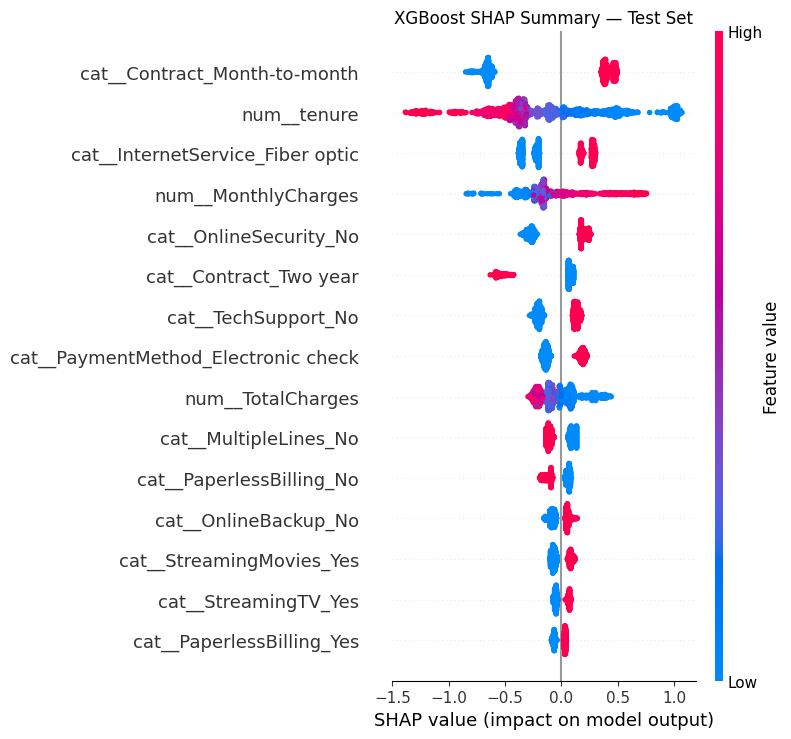

In [41]:
# Explain the fitted XGBoost model with SHAP.
# Install SHAP in a separate cell only if the import fails and
# package installation is permitted in your environment.

import shap
import numpy as np
import matplotlib.pyplot as plt

# Get the already-fitted XGBoost pipeline.
xgb_pipeline = final_models["XGBoost"]
xgb_classifier = xgb_pipeline.named_steps["classifier"]
xgb_preprocessor = xgb_pipeline.named_steps["preprocessor"]

# Transform test data using the fitted preprocessing step.
X_test_transformed = xgb_preprocessor.transform(X_test)

# SHAP TreeExplainer generally works most conveniently with
# a dense matrix for this small Telco dataset.
if hasattr(X_test_transformed, "toarray"):
    X_test_shap = X_test_transformed.toarray()
else:
    X_test_shap = np.asarray(X_test_transformed)

# Retrieve the transformed feature names.
feature_names = xgb_preprocessor.get_feature_names_out()

# Explain the tree model's predictions.
explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(X_test_shap)

# Global summary plot: importance and direction of contributions.
shap.summary_plot(
    shap_values,
    X_test_shap,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title("XGBoost SHAP Summary — Test Set")
plt.tight_layout()
plt.show()